# Embeddings - sözlərin məna əks etditrən ədədi vektor şəklində göstərilməsi

In [3]:
from unittest import result

import gensim # Word2Vec, Doc2Vec kimi modul və modellərlə işləmək üçün kitabxana
from gensim.models import Word2Vec
from gensim import downloader as api

import numpy as np

import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

print(gensim.__version__)

4.4.0


# 1. Word Embeddings

In [15]:
vocab = ['it', 'pişik', 'quş', 'balıq', 'fil']

print("One Hot Encoding:")
print('-' * 50)

for i, word in enumerate(vocab):
    one_hot = np.zeros(len(vocab), dtype=int)
    one_hot[i] = 1
    print(f'{word:10}: {one_hot}')

print('-' * 50)
print('Dense embeddings:')
print('-' * 50)
embeddings_index = {
    'it':np.array([0.8, 0.2, -0.1, 0.5]), # Ev heyvanları
    'pişik':np.array([0.7, 0.3, -0.2, 0.5]), # bənzər
    'quş':np.array([0.1, 0.9, 0.8, -0.1]), # uçanlar - fərqli
    'balıq':np.array([-0.5, 0.1, 0.1, 0.9]), # üzənlər tamam fərqli
    'fil':np.array([0.6, 0.4, -0.3, 0.4]) # iri heyvanlar
}

for word, vec in embeddings_index.items():
    print(f'{word:10}: {vec}')

One Hot Encoding:
--------------------------------------------------
it        : [1 0 0 0 0]
pişik     : [0 1 0 0 0]
quş       : [0 0 1 0 0]
balıq     : [0 0 0 1 0]
fil       : [0 0 0 0 1]
--------------------------------------------------
Dense embeddings:
--------------------------------------------------
it        : [ 0.8  0.2 -0.1  0.5]
pişik     : [ 0.7  0.3 -0.2  0.5]
quş       : [ 0.1  0.9  0.8 -0.1]
balıq     : [-0.5  0.1  0.1  0.9]
fil       : [ 0.6  0.4 -0.3  0.4]


kosinusial bənzərlik

$$
\cos{(\theta)} = \frac{A \cdot B}{\|A\| \times \|B\|}
$$

- $A$ $B$ - müqayisə etdiyimiz vektorlar
- $A \cdot B$ - vektorların skalyar hasili (Dot product)
- $\|A\|$- A vektorunun uzunluğu (Magnitude)
- $\|B\|$- B vektorunun uzunluğu (Magnitude)
- $\theta$ - iki vector arasında bucaq

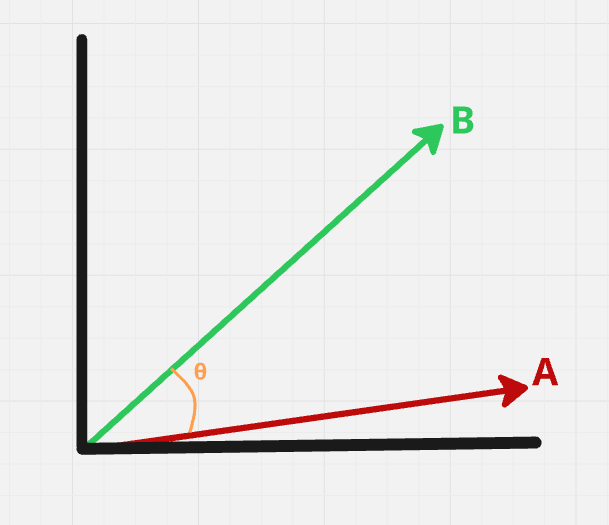
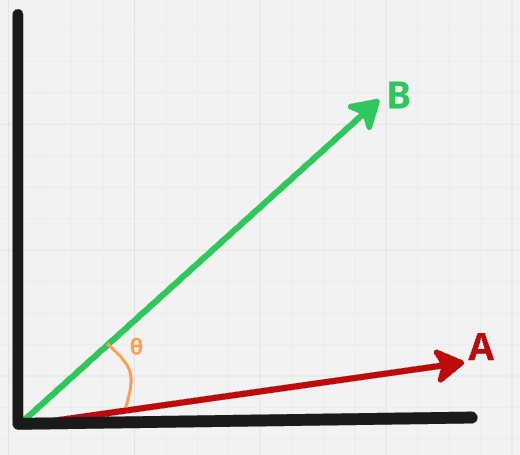
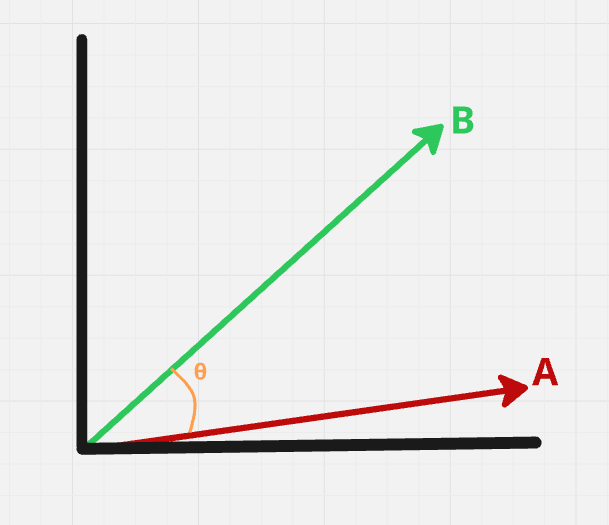

In [16]:
# vektorlar arasında kosinusial bənzərliklərin hesablanması
def cosine_similarity(vec1, vec2):
    dot_product = np.dot(vec1, vec2)

    norm1 = np.linalg.norm(vec1) # = sqrt(a1² + a2² + ...)
    norm2 = np.linalg.norm(vec2) # = sqrt(b1² + b2² + ...)

    return dot_product/(norm1 * norm2)

print('Cosine Similarity:')
print('-' * 50)

words = list(embeddings_index.keys())

for i in range(len(words)):
    for j in range(i+1, len(words)):
        word1, word2 = words[i], words[j]
        sim = cosine_similarity(embeddings_index[word1], embeddings_index[word2])
        print(f'{word1:10} - {word2:10} =  {sim}')

Cosine Similarity:
--------------------------------------------------
it         - pişik      =  0.9841616856627443
it         - quş        =  0.11059124777543396
it         - balıq      =  0.05954913341754135
it         - fil        =  0.9285767423913251
pişik      - quş        =  0.1149542569667464
pişik      - balıq      =  0.11348048444153172
pişik      - fil        =  0.9774284999977502
quş        - balıq      =  0.023809523809523815
quş        - fil        =  0.13159033899195383
balıq      - fil        =  0.07676103107863971


# 2. Word2Vec: Öz modellərimizin öyrədilməsi

In [17]:
import json
with open("word2vec_korpus.json", "r", encoding="utf-8") as file:
    corpus = json.load(file)


print(f'{len(corpus)} sentences found')
print(f'Sentences example {corpus[0]}')

all_words = set()
for sentence in corpus:
    all_words.update(sentence)
print(f'{len(all_words)} unique words found')

1000 sentences found
Sentences example ['proqramlaşdırma', 'dərsində', 'müəllim', 'python', 'java', 'və', 'csharp', 'dillərinin', 'oxşar', 'tərəflərini', 'izah', 'edir', 'və', 'komanda', 'üzvləri', 'layihənin', 'kodunu', 'birlikdə', 'oxuyur', 'və', 'təkmilləşdirirlər']
620 unique words found


In [18]:
model = Word2Vec(
    sentences=corpus,
    vector_size=50,
    window=5,
    min_count=1,
    workers=4,
    epochs=100,
    sg=1 # sg=1 Skip-gram (sözə görə kontekst), sg=0  CBOW (kontekstə görə söz)
)

print(len(model.wv))
print(model.wv.vector_size)
print(list(model.wv.key_to_index.keys())[:5])

620
50
['və', 'edir', 'zamanda', 'eyni', 'bu']


In [19]:
python_vector = model.wv['python']
java_vector = model.wv['java']

print(python_vector[:10])
print(java_vector[:10])

[-0.6112834  -0.83251435  0.13609238 -1.079469   -0.28407276 -0.1353101
 -0.11721277  0.7324215   0.6254473   0.5717824 ]
[-0.02180859 -0.05728998  0.25179264  0.7524613  -0.0087118   0.638214
  0.66729796  0.13404165 -0.8756753   0.21695578]


In [20]:
similar_to_python = model.wv.most_similar('python', topn=10)

for word, similarity in similar_to_python:
    print(f'{word:10}: {similarity:.4f}')

print('-' * 50)
similar_to_dog = model.wv.most_similar('it', topn=10)

for word, similarity in similar_to_dog:
    print(f'{word:10}: {similarity:.4f}')

məşqlərlə : 0.5455
dillərində: 0.5380
java      : 0.5339
emalı     : 0.5075
kitabxanaları: 0.4996
dəyişənləri: 0.4867
dərsində  : 0.4858
dövrləri  : 0.4821
yazmaq    : 0.4784
avtomatlaşdırma: 0.4753
--------------------------------------------------
həyətdə   : 0.7022
sadiq     : 0.6968
üsullarla : 0.6735
hekayələr : 0.6646
danışırlar: 0.6639
qururlar  : 0.6555
qaçır     : 0.6503
insanların: 0.6490
insanlarla: 0.6332
haqqında  : 0.6244


In [21]:
similar_python_to_java = model.wv.similarity('python', 'java')
print(f'Similar to Python: {similar_python_to_java}')

similar_python_to_csharp = model.wv.similarity('python', 'csharp')
print(f'Similar to Python: {similar_python_to_csharp}')



Similar to Python: 0.5338689088821411
Similar to Python: 0.3983297348022461


# Hazır modellərin istifadəsi

In [22]:
available_models = api.info()['models']
for name, info in list(available_models.items()):
    size_mb = info.get('file_size', 0) / (1024 * 1024)
    print(f'name: {name}, size: {size_mb:.2f} MB')

name: fasttext-wiki-news-subwords-300, size: 958.45 MB
name: conceptnet-numberbatch-17-06-300, size: 1168.73 MB
name: word2vec-ruscorpora-300, size: 198.77 MB
name: word2vec-google-news-300, size: 1662.79 MB
name: glove-wiki-gigaword-50, size: 65.98 MB
name: glove-wiki-gigaword-100, size: 128.08 MB
name: glove-wiki-gigaword-200, size: 252.09 MB
name: glove-wiki-gigaword-300, size: 376.09 MB
name: glove-twitter-25, size: 104.79 MB
name: glove-twitter-50, size: 199.52 MB
name: glove-twitter-100, size: 387.13 MB
name: glove-twitter-200, size: 758.53 MB
name: __testing_word2vec-matrix-synopsis, size: 0.00 MB


In [23]:
print('-'*40)
print('glove-twitter-25')
glove_model = api.load('glove-twitter-25')
print(f"Dictionary length: {len(glove_model)}" )
print(f'Vector size: {glove_model.vector_size}' )

----------------------------------------
glove-twitter-25
[==================================================] 100.0% 104.8/104.8MB downloaded
Dictionary length: 1193514
Vector size: 25


In [27]:
print('-'*40)
print('king similarity words')
print('-'*40)

for word, similarity in glove_model.most_similar('king', topn=5):
    print(f'{word:10}: {similarity:.4f}')

print('-'*40)
print('computer similarity words')
print('-'*40)

for word, similarity in glove_model.most_similar('computer', topn=5):
    print(f'{word:10}: {similarity:.4f}')

----------------------------------------
king similarity words
----------------------------------------
prince    : 0.9337
queen     : 0.9202
aka       : 0.9177
lady      : 0.9163
jack      : 0.9147
----------------------------------------
king similarity words
----------------------------------------
camera    : 0.9078
cell      : 0.8919
server    : 0.8745
device    : 0.8694
wifi      : 0.8631


# Embeding vectorlar arasında riyazi əməliyyatlar

1. king - man + woman = queen
2. paris - france + italy = roma

In [41]:
result = glove_model.most_similar(
    positive=['king', 'woman'], negative=['man'], topn=5
)

for word, similarity in result:
    print(f'{word:10}: {similarity:.4f}')

print('-'*40)

result = glove_model.most_similar(
    positive=['paris', 'italy'], negative=['france'], topn=5
)

for word, similarity in result:
    print(f'{word:10}: {similarity:.4f}')

meets     : 0.8842
prince    : 0.8322
queen     : 0.8257
’s        : 0.8174
crow      : 0.8135
----------------------------------------
brazil    : 0.8409
thailand  : 0.7927
milan     : 0.7709
roma      : 0.7669
regina    : 0.7601


In [44]:
words_list = [
    ['book', 'novel', 'apple', 'word'],
    ['apple', 'city', 'pear', 'apricot'],
    ['red', 'green', 'blue', 'car'],
    ['game', 'city', 'state', 'country']
]

for words in words_list:
    try:
        odd_one = glove_model.doesnt_match(words)
        print(f'{words} - {odd_one}')
    except KeyError as e:
        print(e)

['book', 'novel', 'apple', 'word'] - apple
['apple', 'city', 'pear', 'apricot'] - city
['red', 'green', 'blue', 'car'] - car
['game', 'city', 'state', 'country'] - game


In [45]:
words_to_visualize = [
    "cat", "dog", "bird", "fish", "horse",
    "russia", "france", "germany", "japan", "china",
    "red", "blue", "green", "yellow", "black",
    "pizza", "burger", "sushi", "pasta", "rice"
]

words_in_model = [
    w for w in words_to_visualize
    if w in glove_model
]

vectors = np.array([
    glove_model[word] for word in words_in_model
])

print(f"Vizualizasiya üçün sözlərin sayı: {len(words_in_model)}")
print(f"Vektorların ölçüsü: {vectors.shape}")

Vizualizasiya üçün sözlərin sayı: 20
Vektorların ölçüsü: (20, 25)


t-SNE-dən sonra vektorların ölçüsü: (20, 2)


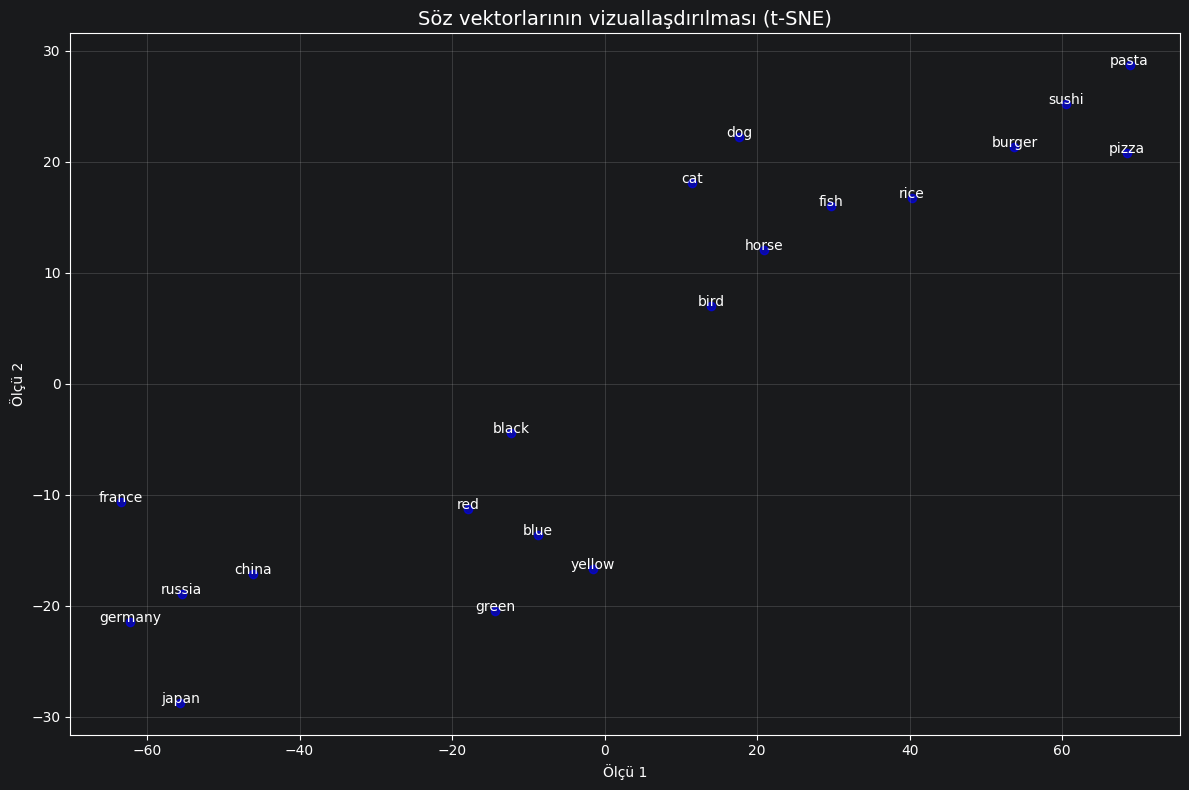

In [46]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=5
)

vectors_2d = tsne.fit_transform(vectors)

print(f"t-SNE-dən sonra vektorların ölçüsü: {vectors_2d.shape}")

plt.figure(figsize=(12, 8))

plt.scatter(
    vectors_2d[:, 0],
    vectors_2d[:, 1],
    c='blue',
    alpha=0.6
)

for i, word in enumerate(words_in_model):
    plt.annotate(
        word,
        xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
        fontsize=10,
        ha='center'
    )

plt.title("Söz vektorlarının vizuallaşdırılması (t-SNE)", fontsize=14)
plt.xlabel("Ölçü 1")
plt.ylabel("Ölçü 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()